# Notebook 05.2 — Validação comparativa de C2 e C3 (CPC 2023)

**Objetivo:** comparar os cenários C2 (oito indicadores) e C3 (quatro dimensões sintéticas), examinando K=2 a 8, a silhueta relativa a uma referência simulada, a estabilidade global e a estabilidade dos pares dos cursos da PUC-Rio. **Não há escolha automática definitiva de cenário ou K.**

Esta é uma análise exploratória adicional: os dados de 2023 já foram examinados nos notebooks anteriores. Os resultados não constituem uma validação externa independente. Os arquivos são salvos em `resultados_notebook_05_2/BASE_COMPLETA/`.

## 1. Preparação e parâmetros
Execute de cima para baixo. Coloque este notebook na pasta principal do projeto, junto à pasta `dados`.

In [1]:
from pathlib import Path
import itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import norm, rankdata
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

K_VALORES = list(range(2, 9))
SEMENTES_REFERENCIA = list(range(42, 52))  # 10 divisões; reduza a 5 para teste rápido
SEMENTES_ESTABILIDADE = list(range(42, 72))  # 30 reamostragens
TEST_SIZE = 0.20
N_INIT = 20
CODIGO_IES_PUC = 528
SEMENTE_KMEANS = 42
SILHUETA_AMOSTRA = 500  # mesma amostra para real e nulo em cada repetição
PASTA_PROJETO = Path.cwd()
ARQUIVO = PASTA_PROJETO/'dados'/'processados'/'base_analitica_1907_cursos.csv'
if not ARQUIVO.exists():
    ARQUIVO = PASTA_PROJETO/'base_analitica_1907_cursos.csv'
if not ARQUIVO.exists():
    raise FileNotFoundError('Base CSV não encontrada. Salve o notebook na pasta principal do projeto.')
PASTA_SAIDA = PASTA_PROJETO/'resultados_notebook_05_2'/'BASE_COMPLETA'
PASTA_SAIDA.mkdir(parents=True,exist_ok=True)
base = pd.read_csv(ARQUIVO,encoding='utf-8-sig')
base.columns=base.columns.str.replace('\ufeff','',regex=False).str.strip()
INDICADORES=['Enade_2023','IDD_2023','Mestres_2023','Doutores_2023',
             'Regime_Trabalho_2023','Organizacao_Didatica_2023',
             'Infraestrutura_2023','Oportunidades_2023']
necessarias=INDICADORES+['Código da IES','Código do Curso','Area_2023']
assert set(necessarias).issubset(base.columns), set(necessarias)-set(base.columns)
for c in INDICADORES: base[c]=pd.to_numeric(base[c],errors='coerce')
base=base.loc[np.isfinite(base[INDICADORES].to_numpy(dtype=float)).all(axis=1)].reset_index(drop=True)
assert not base.duplicated(['Código da IES','Código do Curso']).any()
print('Cursos elegíveis:',len(base),'| Áreas:',base.Area_2023.nunique(),'| PUC-Rio:',pd.to_numeric(base['Código da IES'],errors='coerce').eq(CODIGO_IES_PUC).sum())
print('Saídas:',PASTA_SAIDA)


Cursos elegíveis: 1907 | Áreas: 10 | PUC-Rio: 8
Saídas: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_05_2\BASE_COMPLETA


## 2. Representações C2 e C3
Os pesos de C3 reproduzem o procedimento usado nos notebooks anteriores; não devem ser confundidos com uma demonstração da fórmula oficial integral do CPC.

In [2]:
def representacao(df,cenario):
    if cenario=='C2_8IND': return df[INDICADORES].copy()
    if cenario=='C3_4DIM':
        return pd.DataFrame({
            'ENADE':df['Enade_2023'],
            'IDD':df['IDD_2023'],
            'Condicoes_Formacao':(7.5*df['Organizacao_Didatica_2023']+5*df['Infraestrutura_2023']+2.5*df['Oportunidades_2023'])/15,
            'Corpo_Docente':(7.5*df['Mestres_2023']+15*df['Doutores_2023']+7.5*df['Regime_Trabalho_2023'])/30
        },index=df.index)
    raise ValueError(cenario)

CENARIOS=['C2_8IND','C3_4DIM']
DADOS={c:representacao(base,c) for c in CENARIOS}
def ajustar(X,k):
    return KMeans(n_clusters=k,random_state=SEMENTE_KMEANS,n_init=N_INIT).fit(X)
def silhueta(X,y,seed):
    if len(np.unique(y))<2: return np.nan
    return silhouette_score(X,y,sample_size=min(SILHUETA_AMOSTRA,len(X)),random_state=seed)
for c,X in DADOS.items(): print(c,X.shape, list(X.columns))


C2_8IND (1907, 8) ['Enade_2023', 'IDD_2023', 'Mestres_2023', 'Doutores_2023', 'Regime_Trabalho_2023', 'Organizacao_Didatica_2023', 'Infraestrutura_2023', 'Oportunidades_2023']
C3_4DIM (1907, 4) ['ENADE', 'IDD', 'Condicoes_Formacao', 'Corpo_Docente']


## 3. Referência simulada sem mistura explícita de grupos

Geramos dados de referência com **cópula gaussiana e marginais empíricas**. Ela aproxima as distribuições marginais e a dependência por postos, mas **não garante preservar exatamente as correlações de Pearson nem todos os padrões multivariados**. Portanto, representa uma hipótese nula operacional, não uma prova de inexistência de grupos.

Para cada divisão, o escalonamento é ajustado **somente no treino real**. A amostra nula é gerada a partir desse treino, transformada com o mesmo escalonador e submetida ao mesmo K-means. O ganho é a diferença de silhuetas no treino, com amostragem equivalente. Os resultados são exploratórios, pois os cenários foram definidos após análises anteriores.

In [3]:
def referencia_copula(X,seed):
    rng=np.random.default_rng(seed)
    X=np.asarray(X,dtype=float); n,p=X.shape
    U=np.column_stack([(rankdata(X[:,j],method='average')-0.5)/n for j in range(p)])
    Z=norm.ppf(np.clip(U,1e-6,1-1e-6))
    R=np.corrcoef(Z,rowvar=False)
    if p==1: R=np.array([[1.]])
    R=np.nan_to_num(R,nan=0.)
    vals,vecs=np.linalg.eigh(R)
    R=(vecs*np.maximum(vals,1e-6))@vecs.T
    d=np.sqrt(np.diag(R));R=R/d[:,None]/d[None,:]
    z=rng.multivariate_normal(np.zeros(p),R,size=n)
    u=norm.cdf(z)
    out=np.column_stack([np.quantile(X[:,j],u[:,j]) for j in range(p)])
    return out

log_nulo=[]
inicio=time.time()
for c in CENARIOS:
    D=DADOS[c]
    for seed in SEMENTES_REFERENCIA:
        idx_tr,_=train_test_split(np.arange(len(D)),test_size=TEST_SIZE,random_state=seed)
        Xbr=D.iloc[idx_tr].to_numpy()
        scaler=StandardScaler().fit(Xbr)
        Xreal=scaler.transform(Xbr)
        Xnulo=scaler.transform(referencia_copula(Xbr,seed+10000))
        for k in K_VALORES:
            mr=ajustar(Xreal,k);mn=ajustar(Xnulo,k)
            sr=silhueta(Xreal,mr.labels_,seed)
            sn=silhueta(Xnulo,mn.labels_,seed)
            log_nulo.append({'Cenario':c,'K':k,'Semente':seed,'Silhueta_real':sr,
                             'Silhueta_nula':sn,'Ganho':sr-sn,
                             'DB_real':davies_bouldin_score(Xreal,mr.labels_),
                             'Menor_grupo':np.bincount(mr.labels_,minlength=k).min()})
log_nulo=pd.DataFrame(log_nulo)
resumo_nulo=log_nulo.groupby(['Cenario','K'],as_index=False).agg(
    Silhueta_real=('Silhueta_real','mean'),Silhueta_nula=('Silhueta_nula','mean'),
    Ganho_medio=('Ganho','mean'),Ganho_dp=('Ganho','std'),
    DB_real=('DB_real','mean'),Menor_grupo_min=('Menor_grupo','min'))
print('Tempo (s):',round(time.time()-inicio,1))
display(resumo_nulo.round(4))


Tempo (s): 68.9


,Cenario,K,Silhueta_real,Silhueta_nula,Ganho_medio,Ganho_dp,DB_real,Menor_grupo_min
0,C2_8IND,2,0.2152,0.1988,0.0163,0.0142,1.7003,617
1,C2_8IND,3,0.2279,0.1911,0.0368,0.0100,1.4115,432
2,C2_8IND,4,0.2391,0.1846,0.0544,0.0152,1.3679,218
3,C2_8IND,5,0.2298,0.1738,0.0560,0.0248,1.4326,158
4,C2_8IND,6,0.2025,0.1650,0.0375,0.0106,1.4603,125
5,C2_8IND,7,0.1909,0.1579,0.0331,0.0178,1.5045,65
6,C2_8IND,8,0.1758,0.1528,0.0230,0.0101,1.5120,64
7,C3_4DIM,2,0.2980,0.2664,0.0315,0.0116,1.2693,498
8,C3_4DIM,3,0.2768,0.2394,0.0374,0.0154,1.3015,398
9,C3_4DIM,4,0.2778,0.2364,0.0414,0.0092,1.1768,268


## 4. Gráficos da referência simulada
Compare os ganhos e sua variabilidade; diferenças pequenas não devem ser tratadas como conclusivas.

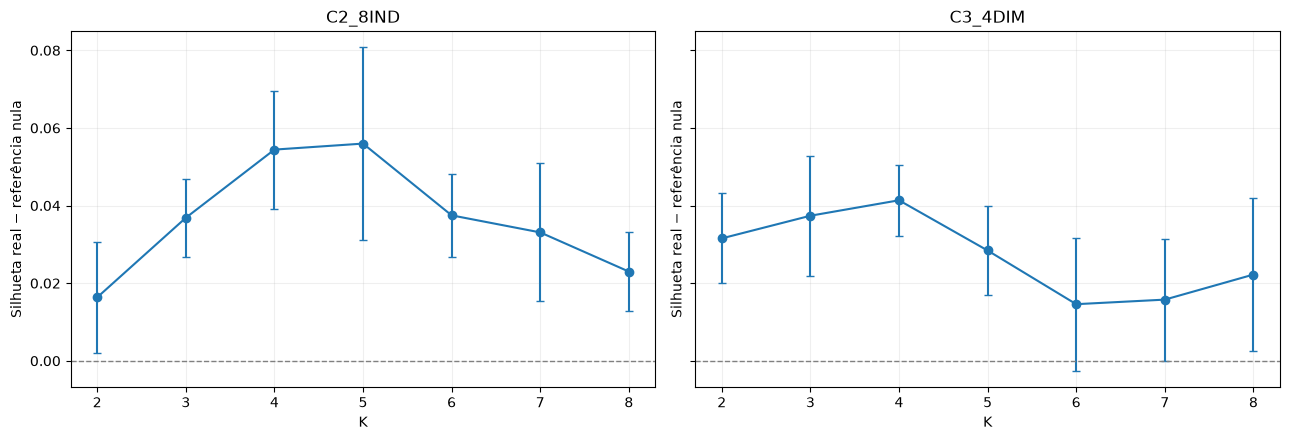

In [4]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5),sharey=True)
for ax,c in zip(axs,CENARIOS):
    t=resumo_nulo.query('Cenario == @c')
    ax.errorbar(t.K,t.Ganho_medio,yerr=t.Ganho_dp,marker='o',capsize=3)
    ax.axhline(0,color='gray',linestyle='--',linewidth=1)
    ax.set(title=c,xlabel='K',ylabel='Silhueta real − referência nula')
    ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(PASTA_SAIDA/'01_ganho_silhueta_nula.png',dpi=160);plt.show()


## 5. Estabilidade global com 30 divisões

Cada modelo é ajustado em 80% dos cursos e prediz **o mesmo conjunto completo** para permitir ARI entre partições. Isso mede estabilidade sob reamostragem, mas inclui sobreposição entre os treinos e **não é validação externa**.

In [5]:
log_est=[]; rotulos={}; modelos={}
inicio=time.time()
for c in CENARIOS:
    D=DADOS[c]
    for k in K_VALORES:
        chave=(c,k);rotulos[chave]={};modelos[chave]={}
        for seed in SEMENTES_ESTABILIDADE:
            idx_tr,idx_val=train_test_split(np.arange(len(D)),test_size=TEST_SIZE,random_state=seed)
            scaler=StandardScaler().fit(D.iloc[idx_tr])
            Xtr=scaler.transform(D.iloc[idx_tr]);Xval=scaler.transform(D.iloc[idx_val]);Xall=scaler.transform(D)
            mod=ajustar(Xtr,k)
            yval=mod.predict(Xval)
            rotulos[chave][seed]=mod.predict(Xall)
            modelos[chave][seed]=(scaler,mod)
            log_est.append({'Cenario':c,'K':k,'Semente':seed,
                'Silhueta_validacao':silhueta(Xval,yval,seed),
                'DB_validacao':davies_bouldin_score(Xval,yval) if len(np.unique(yval))>1 else np.nan})
log_est=pd.DataFrame(log_est)
linhas=[]
for (c,k),rep in rotulos.items():
    aris=[adjusted_rand_score(rep[a],rep[b]) for a,b in itertools.combinations(rep,2)]
    linhas.append({'Cenario':c,'K':k,'ARI_medio':np.mean(aris),'ARI_min':np.min(aris),'ARI_dp':np.std(aris,ddof=1)})
resumo_est=pd.DataFrame(linhas).merge(log_est.groupby(['Cenario','K'],as_index=False).agg(
    Silhueta_validacao=('Silhueta_validacao','mean'),DB_validacao=('DB_validacao','mean')),on=['Cenario','K'])
print('Tempo (s):',round(time.time()-inicio,1));display(resumo_est.round(4))


Tempo (s): 172.6


,Cenario,K,ARI_medio,ARI_min,ARI_dp,Silhueta_validacao,DB_validacao
0,C2_8IND,2,0.9045,0.7603,0.0670,0.2158,1.7120
1,C2_8IND,3,0.9399,0.8485,0.0284,0.2243,1.4279
2,C2_8IND,4,0.9609,0.9036,0.0163,0.2366,1.3744
3,C2_8IND,5,0.9305,0.8050,0.0337,0.2282,1.4361
4,C2_8IND,6,0.8665,0.7047,0.0554,0.2030,1.4512
5,C2_8IND,7,0.6642,0.4822,0.1301,0.1772,1.5377
6,C2_8IND,8,0.6395,0.3919,0.1149,0.1673,1.5376
7,C3_4DIM,2,0.9473,0.7754,0.0423,0.2911,1.2800
8,C3_4DIM,3,0.9335,0.6901,0.0571,0.2726,1.3105
9,C3_4DIM,4,0.9392,0.8492,0.0221,0.2745,1.1810


## 6. Estabilidade local de cada curso da PUC-Rio

O Jaccard compara, para um mesmo curso, o **conjunto de outros cursos classificados junto com ele** entre duas reamostragens. A comparação é feita no mesmo universo de 1.907 cursos. Um grupo pequeno pode produzir Jaccard mais volátil. Reportamos média e mínimo entre pares de modelos; não usamos os números dos experimentos anteriores como se fossem diretamente equivalentes.

In [7]:
idx_puc=np.flatnonzero(pd.to_numeric(base['Código da IES'],errors='coerce').eq(CODIGO_IES_PUC).to_numpy())
assert len(idx_puc)>0,'Não há cursos da PUC-Rio na base elegível.'
linhas=[]
for c in CENARIOS:
    for k in [2,4]:
        reps=rotulos[(c,k)]
        for idx in idx_puc:
            vals=[]
            for a,b in itertools.combinations(reps,2):
                ya,yb=reps[a],reps[b]
                A=set(np.flatnonzero(ya==ya[idx]));B=set(np.flatnonzero(yb==yb[idx]))
                A.discard(idx);B.discard(idx)
                vals.append(len(A&B)/len(A|B) if A|B else 1.)
            linhas.append({'Cenario':c,'K':k,'Código da IES':base.loc[idx,'Código da IES'],
                'Código do Curso':base.loc[idx,'Código do Curso'],
                'Area_2023':base.loc[idx,'Area_2023'],
                'Jaccard_medio':np.mean(vals),'Jaccard_minimo':np.min(vals),
                'Jaccard_dp':np.std(vals,ddof=1)})
jaccard_puc=pd.DataFrame(linhas)
display(jaccard_puc.sort_values(['Código do Curso','Cenario','K']).round(4))
print('Resumo dos cursos da PUC-Rio:')
display(jaccard_puc.groupby(['Cenario','K'],as_index=False).agg(
    Jaccard_medio_cursos=('Jaccard_medio','mean'),
    Pior_Jaccard_medio=('Jaccard_medio','min'),
    Pior_Jaccard_minimo=('Jaccard_minimo','min')).round(4))


,Cenario,K,Código da IES,Código do Curso,Area_2023,Jaccard_medio,Jaccard_minimo,Jaccard_dp
4,C2_8IND,2,528,23702,5902,0.9452,0.8617,0.0380
12,C2_8IND,4,528,23702,5902,0.9827,0.9451,0.0105
20,C3_4DIM,2,528,23702,5902,0.9627,0.8454,0.0296
28,C3_4DIM,4,528,23702,5902,0.9820,0.9450,0.0088
1,C2_8IND,2,528,29445,5710,0.9452,0.8617,0.0380
9,C2_8IND,4,528,29445,5710,0.9827,0.9451,0.0105
17,C3_4DIM,2,528,29445,5710,0.9627,0.8454,0.0296
25,C3_4DIM,4,528,29445,5710,0.9820,0.9450,0.0088
2,C2_8IND,2,528,29446,5806,0.9452,0.8617,0.0380
10,C2_8IND,4,528,29446,5806,0.9716,0.9195,0.0160


Resumo dos cursos da PUC-Rio:


,Cenario,K,Jaccard_medio_cursos,Pior_Jaccard_medio,Pior_Jaccard_minimo
0,C2_8IND,2,0.9498,0.9452,0.8617
1,C2_8IND,4,0.9723,0.9437,0.8734
2,C3_4DIM,2,0.9692,0.9627,0.8454
3,C3_4DIM,4,0.9251,0.7033,0.0021


## 7. Comparação entre C2 e C3 com K = 4
O ARI entre cenários compara as partições sem depender dos números arbitrários dos grupos. O percentual de concordância após alinhamento é complementar.

In [8]:
from scipy.optimize import linear_sum_assignment
comparacoes=[]
for seed in SEMENTES_ESTABILIDADE:
    a=rotulos[('C2_8IND',4)][seed];bb=rotulos[('C3_4DIM',4)][seed]
    tab=pd.crosstab(a,bb).reindex(index=range(4),columns=range(4),fill_value=0).to_numpy()
    rr,cc=linear_sum_assignment(-tab)
    comparacoes.append({'Semente':seed,'ARI_C2_C3':adjusted_rand_score(a,bb),
                         'Concordancia_alinhada':tab[rr,cc].sum()/len(a)})
comparacao_cenarios=pd.DataFrame(comparacoes)
display(comparacao_cenarios.describe().round(4))


,Semente,ARI_C2_C3,Concordancia_alinhada
count,30.0000,30.0000,30.0000
mean,56.5000,0.7345,0.8924
std,8.8034,0.0113,0.0052
min,42.0000,0.7111,0.8825
25%,49.2500,0.7278,0.8895
50%,56.5000,0.7362,0.8933
75%,63.7500,0.7414,0.8956
max,71.0000,0.7608,0.9046


## 8. Perfis dos centroides (K = 4)

Para permitir interpretação, os centroides são apresentados **na escala original de cada representação**. A numeração dos grupos é arbitrária e não deve ser comparada diretamente entre cenários.

In [9]:
centroides=[]
for c in CENARIOS:
    scaler,mod=modelos[(c,4)][42]
    Xorig=scaler.inverse_transform(mod.cluster_centers_)
    tabela=pd.DataFrame(Xorig,columns=DADOS[c].columns)
    tabela.insert(0,'Grupo',range(4));tabela.insert(0,'Cenario',c)
    centroides.append(tabela)
    print(c);display(tabela.round(3))
centroides=pd.concat(centroides,ignore_index=True)


C2_8IND


,Cenario,Grupo,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023
0,C2_8IND,0,1.921,1.758,4.525,3.443,4.299,2.259,2.466,2.361
1,C2_8IND,1,2.421,2.589,4.501,2.798,4.000,4.036,4.261,4.121
2,C2_8IND,2,3.803,3.636,4.709,4.060,4.877,2.270,2.619,3.145
3,C2_8IND,3,1.997,2.186,2.251,1.305,2.664,2.946,2.998,2.739


C3_4DIM


,Cenario,Grupo,ENADE,IDD,Condicoes_Formacao,Corpo_Docente
0,C3_4DIM,0,1.957,2.079,3.040,2.001
1,C3_4DIM,1,1.897,1.721,2.427,4.000
2,C3_4DIM,2,3.809,3.698,2.574,4.367
3,C3_4DIM,3,2.480,2.673,4.151,3.575


## 9. Síntese para decisão e exportação

**Critérios a discutir conjuntamente:** (a) ganho sobre referência nula e incerteza, (b) ARI global, (c) Jaccard dos cursos da PUC-Rio, (d) interpretabilidade dos centroides. Não existe pontuação única automaticamente ótima. A análise de 2023 já é exploratória e não pode ser apresentada como confirmação independente.

**Após executar:** salve o `.ipynb` com as saídas e envie-o para revisão antes de definir o cenário principal e iniciar o notebook 06.

In [10]:
resumo_decisao=resumo_nulo.merge(resumo_est,on=['Cenario','K'])
resumo_puc=jaccard_puc.groupby(['Cenario','K'],as_index=False).agg(
    Jaccard_medio_PUC=('Jaccard_medio','mean'),Jaccard_minimo_PUC=('Jaccard_minimo','min'))
resumo_decisao=resumo_decisao.merge(resumo_puc,on=['Cenario','K'],how='left')
print('Quadro de decisão (K = 2 a 8):')
display(resumo_decisao.round(4))
for nome,tabela in {'01_referencia_simulada':log_nulo,'02_resumo_referencia':resumo_nulo,
                    '03_estabilidade_repeticoes':log_est,'04_resumo_estabilidade':resumo_est,
                    '05_jaccard_cursos_PUC':jaccard_puc,'06_comparacao_C2_C3':comparacao_cenarios,
                    '07_centroides_K4':centroides,'08_quadro_decisao':resumo_decisao}.items():
    tabela.to_csv(PASTA_SAIDA/f'{nome}.csv',index=False,encoding='utf-8-sig')
print('Exportação concluída em:',PASTA_SAIDA)


Quadro de decisão (K = 2 a 8):


,Cenario,K,Silhueta_real,Silhueta_nula,Ganho_medio,Ganho_dp,DB_real,Menor_grupo_min,ARI_medio,ARI_min,ARI_dp,Silhueta_validacao,DB_validacao,Jaccard_medio_PUC,Jaccard_minimo_PUC
0,C2_8IND,2,0.2152,0.1988,0.0163,0.0142,1.7003,617,0.9045,0.7603,0.0670,0.2158,1.7120,0.9498,0.8617
1,C2_8IND,3,0.2279,0.1911,0.0368,0.0100,1.4115,432,0.9399,0.8485,0.0284,0.2243,1.4279,NaN,NaN
2,C2_8IND,4,0.2391,0.1846,0.0544,0.0152,1.3679,218,0.9609,0.9036,0.0163,0.2366,1.3744,0.9723,0.8734
3,C2_8IND,5,0.2298,0.1738,0.0560,0.0248,1.4326,158,0.9305,0.8050,0.0337,0.2282,1.4361,NaN,NaN
4,C2_8IND,6,0.2025,0.1650,0.0375,0.0106,1.4603,125,0.8665,0.7047,0.0554,0.2030,1.4512,NaN,NaN
5,C2_8IND,7,0.1909,0.1579,0.0331,0.0178,1.5045,65,0.6642,0.4822,0.1301,0.1772,1.5377,NaN,NaN
6,C2_8IND,8,0.1758,0.1528,0.0230,0.0101,1.5120,64,0.6395,0.3919,0.1149,0.1673,1.5376,NaN,NaN
7,C3_4DIM,2,0.2980,0.2664,0.0315,0.0116,1.2693,498,0.9473,0.7754,0.0423,0.2911,1.2800,0.9692,0.8454
8,C3_4DIM,3,0.2768,0.2394,0.0374,0.0154,1.3015,398,0.9335,0.6901,0.0571,0.2726,1.3105,NaN,NaN
9,C3_4DIM,4,0.2778,0.2364,0.0414,0.0092,1.1768,268,0.9392,0.8492,0.0221,0.2745,1.1810,0.9251,0.0021


Exportação concluída em: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_05_2\BASE_COMPLETA
